# SCIKIT-LEARN MASTERY — NOTEBOOK 7
## Chapters 32–38: Feature Selection → Mutual Information → Dimensionality Reduction → PCA Deeply → Unsupervised Learning (Clustering) → Cluster Evaluation → Anomaly Detection

Continuing directly from Notebook 6. This notebook shifts from purely supervised territory into feature reduction and unsupervised learning.

### SCIKIT-LEARN MASTERY PROGRESS
- [x] Chapters 1–31 *(Notebooks 1–6)*
- [x] Feature Selection
- [x] Mutual Information
- [x] Dimensionality Reduction
- [x] PCA Deeply
- [x] Unsupervised Learning / Clustering
- [x] Cluster Evaluation
- [x] Anomaly Detection


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification, make_blobs
np.random.seed(42)


---
# CHAPTER 32 — FEATURE SELECTION

## 1. Concept
`sklearn.feature_selection` reduces the feature set to those genuinely useful — improving interpretability, training speed, and sometimes generalization (fewer irrelevant features means less opportunity to overfit to noise). Three families exist, each with a different tradeoff between speed and how well they account for feature interactions.

## 2. Filter, Wrapper, and Embedded Methods
| Family | How it decides | Speed | Accounts for model/feature interactions? |
|---|---|---|---|
| **Filter** (`VarianceThreshold`, `SelectKBest`) | A statistic computed on each feature independently, no model involved | Fast | No — evaluates features in isolation |
| **Wrapper** (`RFE`, `RFECV`, `SequentialFeatureSelector`) | Repeatedly fits an actual model on feature subsets | Slow (many model fits) | Yes — genuinely measures each subset's real predictive effect |
| **Embedded** (`SelectFromModel`) | Uses a fitted model's own learned importance (coefficients, `feature_importances_`) | Fast (one fit) | Partially — reflects one specific model's view |


In [2]:
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif, SelectFromModel, RFE
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

X_fs, y_fs = make_classification(n_samples=500, n_features=20, n_informative=5, n_redundant=5, random_state=42)
feature_names_fs = [f"f{i}" for i in range(20)]

# --- FILTER: VarianceThreshold -- drops near-constant, low-information features ---
vt = VarianceThreshold(threshold=0.5)
X_vt = vt.fit_transform(X_fs)
print(f"VarianceThreshold: {X_fs.shape[1]} -> {X_vt.shape[1]} features (dropped near-constant ones)")

# --- FILTER: SelectKBest -- top K features by a univariate statistical test ---
skb = SelectKBest(score_func=f_classif, k=8)
X_skb = skb.fit_transform(X_fs, y_fs)
selected_names_skb = np.array(feature_names_fs)[skb.get_support()]
print(f"SelectKBest (f_classif, k=8): selected {list(selected_names_skb)}")


VarianceThreshold: 20 -> 20 features (dropped near-constant ones)
SelectKBest (f_classif, k=8): selected [np.str_('f0'), np.str_('f1'), np.str_('f7'), np.str_('f8'), np.str_('f9'), np.str_('f11'), np.str_('f13'), np.str_('f14')]


In [3]:
# --- EMBEDDED: SelectFromModel -- uses a fitted model's own importance/coefficients ---
sfm = SelectFromModel(RandomForestClassifier(n_estimators=100, random_state=42), threshold="median")
X_sfm = sfm.fit_transform(X_fs, y_fs)
selected_names_sfm = np.array(feature_names_fs)[sfm.get_support()]
print(f"SelectFromModel (RandomForest, threshold='median'): {X_fs.shape[1]} -> {X_sfm.shape[1]} features")
print("Selected:", list(selected_names_sfm))


SelectFromModel (RandomForest, threshold='median'): 20 -> 10 features
Selected: [np.str_('f0'), np.str_('f1'), np.str_('f5'), np.str_('f7'), np.str_('f8'), np.str_('f9'), np.str_('f11'), np.str_('f13'), np.str_('f14'), np.str_('f19')]


In [4]:
# --- WRAPPER: RFE (Recursive Feature Elimination) -- repeatedly fits, drops the WEAKEST feature, repeats ---
rfe = RFE(estimator=LogisticRegression(max_iter=1000), n_features_to_select=8, step=1)
rfe.fit(X_fs, y_fs)
selected_names_rfe = np.array(feature_names_fs)[rfe.support_]
print("RFE (LogisticRegression, n_features_to_select=8):", list(selected_names_rfe))
print("\nRanking (1 = selected, higher = eliminated earlier):")
print(dict(zip(feature_names_fs, rfe.ranking_)))


RFE (LogisticRegression, n_features_to_select=8): [np.str_('f0'), np.str_('f1'), np.str_('f4'), np.str_('f7'), np.str_('f8'), np.str_('f9'), np.str_('f13'), np.str_('f14')]

Ranking (1 = selected, higher = eliminated earlier):
{'f0': np.int64(1), 'f1': np.int64(1), 'f2': np.int64(10), 'f3': np.int64(5), 'f4': np.int64(1), 'f5': np.int64(3), 'f6': np.int64(2), 'f7': np.int64(1), 'f8': np.int64(1), 'f9': np.int64(1), 'f10': np.int64(7), 'f11': np.int64(11), 'f12': np.int64(8), 'f13': np.int64(1), 'f14': np.int64(1), 'f15': np.int64(13), 'f16': np.int64(6), 'f17': np.int64(12), 'f18': np.int64(9), 'f19': np.int64(4)}


### Line-by-Line Explanation
- `VarianceThreshold(threshold=0.5)` — drops any feature whose variance is below the threshold; a purely statistical, model-agnostic filter — useful as a cheap first pass to remove genuinely uninformative (near-constant) columns before any modeling begins.
- `SelectKBest(score_func=f_classif, k=8)` — `f_classif` computes an ANOVA F-statistic per feature (how well each feature alone separates the classes); other `score_func` options include `chi2` (for non-negative features, common with text counts) and `mutual_info_classif` (Chapter 33). Fast, but evaluates each feature **independently**, missing any interaction effects (e.g., two features that are only jointly informative would each look weak alone).
- `SelectFromModel(RandomForestClassifier(...), threshold="median")` — fits the given model once, then keeps only features whose importance exceeds the specified `threshold` (`"median"` keeps the top half; a numeric value is also accepted directly).
- `RFE(estimator=..., n_features_to_select=8)` — the classic wrapper method: fit the model, rank features by importance/coefficient magnitude, **eliminate the single weakest**, refit, repeat — until only `n_features_to_select` remain. Genuinely accounts for how features interact within the specific model used, at real computational cost (many refits).

### `RFECV` — Letting Cross-Validation Choose the Feature Count


RFECV automatically selected 4 features (out of 20)


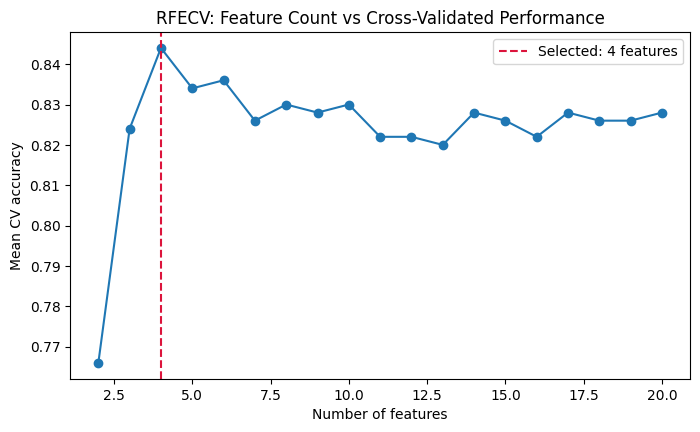

In [5]:
from sklearn.feature_selection import RFECV

rfecv = RFECV(estimator=LogisticRegression(max_iter=1000), cv=5, scoring="accuracy", min_features_to_select=2)
rfecv.fit(X_fs, y_fs)
print(f"RFECV automatically selected {rfecv.n_features_} features (out of {X_fs.shape[1]})")

fig, ax = plt.subplots(figsize=(8, 4.5))
n_scores = len(rfecv.cv_results_["mean_test_score"])
ax.plot(range(rfecv.min_features_to_select, rfecv.min_features_to_select + n_scores), rfecv.cv_results_["mean_test_score"], marker="o")
ax.axvline(rfecv.n_features_, color="crimson", linestyle="--", label=f"Selected: {rfecv.n_features_} features")
ax.set_xlabel("Number of features")
ax.set_ylabel("Mean CV accuracy")
ax.set_title("RFECV: Feature Count vs Cross-Validated Performance")
ax.legend()
plt.show()


### Common Mistakes
- Fitting feature selection (any of these methods) on the **entire** dataset before splitting into train/test — the exact same leakage pattern from Chapter 5/11, now applied to feature selection specifically; feature selectors must be fit only on training data (or, correctly, as a Pipeline step, so cross-validation refits them per fold).
- Assuming a filter method's ranking reflects genuine predictive value when strong feature interactions exist — a feature that's individually weak but powerful in combination with another will be systematically underrated by `SelectKBest`/`f_classif`.
- Using `RFE` on a very large feature set with an expensive model — its many-refit cost can become prohibitive; `SelectFromModel` (one fit) or a filter method is more practical at large scale.

### Best Practices
- Use a fast filter method as an initial coarse pass on very high-dimensional data, then a wrapper/embedded method for final refinement if computationally feasible.
- Always wrap feature selection inside a Pipeline (Chapter 11) so it participates correctly in cross-validation.
- Use `RFECV` when the *right number* of features is itself unknown and worth determining empirically, rather than guessing `n_features_to_select`.

### Interview Insight
**Q: Why might `SelectKBest` miss a genuinely important feature that `RFE` or `SelectFromModel` would correctly keep?**
A: `SelectKBest` (and filter methods generally) score each feature **independently** against the target — a feature that's only predictive in *combination* with another feature (a genuine interaction effect) can score weakly alone and get filtered out, even though it's genuinely valuable to the final model. Wrapper methods (`RFE`) and embedded methods (`SelectFromModel`) both involve an actual fitted model, which can capture at least some of these interaction effects (a tree-based model's importance, for instance, reflects how a feature contributes within actual learned splits, not in isolation).

### Quiz (Chapter 32)
1. What's the key tradeoff between filter, wrapper, and embedded feature selection methods?
2. Why must feature selection be fit only on training data, exactly like any other preprocessing step?
3. What does `RFECV` add on top of plain `RFE`?
4. Why might a genuinely important feature be missed by `SelectKBest` specifically?


---
# CHAPTER 33 — MUTUAL INFORMATION

## 1. Concept
`mutual_info_classif`/`mutual_info_regression` measure the **mutual information** between each feature and the target — a genuinely non-linear, non-parametric dependence measure (unlike correlation, which only captures *linear* relationships). Mutual information is zero if and only if two variables are truly independent; it can detect arbitrary non-linear relationships that Pearson correlation (or `f_classif`'s ANOVA test) would completely miss.


In [6]:
from sklearn.feature_selection import mutual_info_classif

np.random.seed(3)
n_mi = 500
x_linear = np.random.uniform(-3, 3, n_mi)
x_nonlinear = np.random.uniform(-3, 3, n_mi)
x_irrelevant = np.random.uniform(-3, 3, n_mi)

# Target depends LINEARLY on x_linear, NON-LINEARLY (U-shaped) on x_nonlinear, and NOT AT ALL on x_irrelevant
y_mi = ((x_linear + x_nonlinear**2 + np.random.normal(0, 0.5, n_mi)) > 2).astype(int)

X_mi = np.column_stack([x_linear, x_nonlinear, x_irrelevant])
mi_scores = mutual_info_classif(X_mi, y_mi, random_state=42)

from sklearn.feature_selection import f_classif
f_scores, _ = f_classif(X_mi, y_mi)

comparison = pd.DataFrame({
    "feature": ["x_linear", "x_nonlinear (U-shaped)", "x_irrelevant"],
    "mutual_info": mi_scores,
    "f_classif (linear-only test)": f_scores,
})
print(comparison)


                  feature  mutual_info  f_classif (linear-only test)
0                x_linear     0.119949                    134.097888
1  x_nonlinear (U-shaped)     0.227071                      0.599896
2            x_irrelevant     0.000000                      0.271190


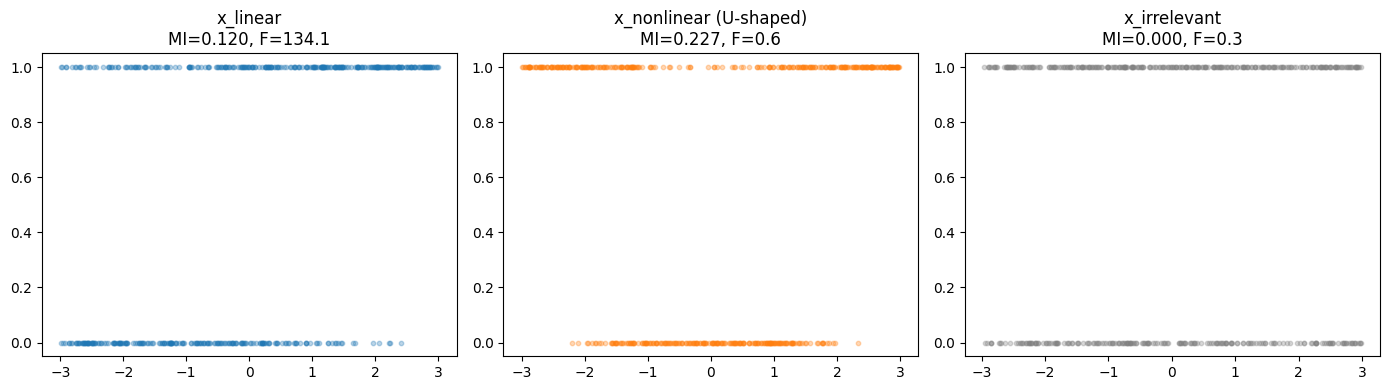

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter(x_linear, y_mi, alpha=0.3, s=10)
axes[0].set_title(f"x_linear\nMI={mi_scores[0]:.3f}, F={f_scores[0]:.1f}")
axes[1].scatter(x_nonlinear, y_mi, alpha=0.3, s=10, color="tab:orange")
axes[1].set_title(f"x_nonlinear (U-shaped)\nMI={mi_scores[1]:.3f}, F={f_scores[1]:.1f}")
axes[2].scatter(x_irrelevant, y_mi, alpha=0.3, s=10, color="gray")
axes[2].set_title(f"x_irrelevant\nMI={mi_scores[2]:.3f}, F={f_scores[2]:.1f}")
plt.tight_layout()
plt.show()


### Interpretation
`x_nonlinear`'s U-shaped relationship with the target is often **underrated by `f_classif`** (a linear-relationship-oriented test) relative to how mutual information scores it — because a U-shape has essentially zero *linear* correlation with the target (positive and negative deviations partially cancel out in a linear test) despite carrying genuine, strong predictive information. `x_irrelevant` should score low on both measures, as expected — a useful sanity check that both methods correctly identify true noise.

### Common Mistakes
- Relying exclusively on `f_classif`/correlation-based filter methods when non-linear feature-target relationships are plausible — silently discards genuinely valuable non-linear features, exactly the risk this chapter demonstrates concretely.
- Treating mutual information scores as directly comparable in magnitude across completely different datasets/problems — they're useful for *relative* ranking within one feature set, less so as an absolute, cross-problem benchmark.
- Forgetting that `mutual_info_classif`/`regression` are stochastic (they use a nearest-neighbor-based estimator internally) — always set `random_state` for reproducibility.

### Best Practices
- Include mutual information alongside (not instead of) linear-relationship-based filters when non-linear relationships are plausible — the two methods are complementary, not redundant.
- Set `random_state` for reproducible mutual information scores.

### Interview Insight
**Q: A feature has a genuine U-shaped (quadratic) relationship with the target, but scores near-zero on a Pearson correlation / ANOVA F-test. Would you conclude it's irrelevant?**
A: No — Pearson correlation and `f_classif`'s F-test specifically measure *linear* association; a symmetric U-shaped relationship can have close to zero linear correlation (positive and negative deviations from the center cancel out) despite the feature carrying substantial genuine predictive information about the target. Mutual information, being a non-parametric measure of *any* statistical dependence (linear or not), would correctly score this feature as informative — this is precisely why mutual-information-based feature selection is a valuable complement to purely linear filter methods, not a redundant alternative.

### Quiz (Chapter 33)
1. What key limitation of Pearson correlation / `f_classif` does mutual information avoid?
2. Why might a U-shaped feature-target relationship score near-zero on a linear test but high on mutual information?
3. Why is `random_state` important when computing mutual information scores?


---
# CHAPTER 34 — DIMENSIONALITY REDUCTION

## 1. Concept
Unlike feature *selection* (choosing a subset of *existing* columns), dimensionality reduction creates **new**, typically fewer, derived features that summarize the original data's structure — trading some interpretability for compactness, noise reduction, and (for visualization) the ability to view high-dimensional data in 2D/3D.

## 2. The Family
| Method | Idea | Use case |
|---|---|---|
| `PCA` | Linear projection onto directions of maximum variance | The default, general-purpose choice — Chapter 35 goes deep |
| `IncrementalPCA` | PCA computed in batches | Datasets too large to fit in memory at once |
| `KernelPCA` | PCA in a kernel-transformed (non-linear) feature space | Non-linear structure PCA alone would miss |
| `TruncatedSVD` | Like PCA but works directly on **sparse** matrices (doesn't require centering) | Text/TF-IDF data (Chapter 63) |
| `NMF` (Non-negative Matrix Factorization) | Decomposition constrained to non-negative components | Data that's inherently non-negative (counts, images, text) — components are often more interpretable ("parts") |
| `FastICA` | Finds statistically **independent** (not just uncorrelated) components | Signal separation problems (e.g., separating mixed audio sources) |


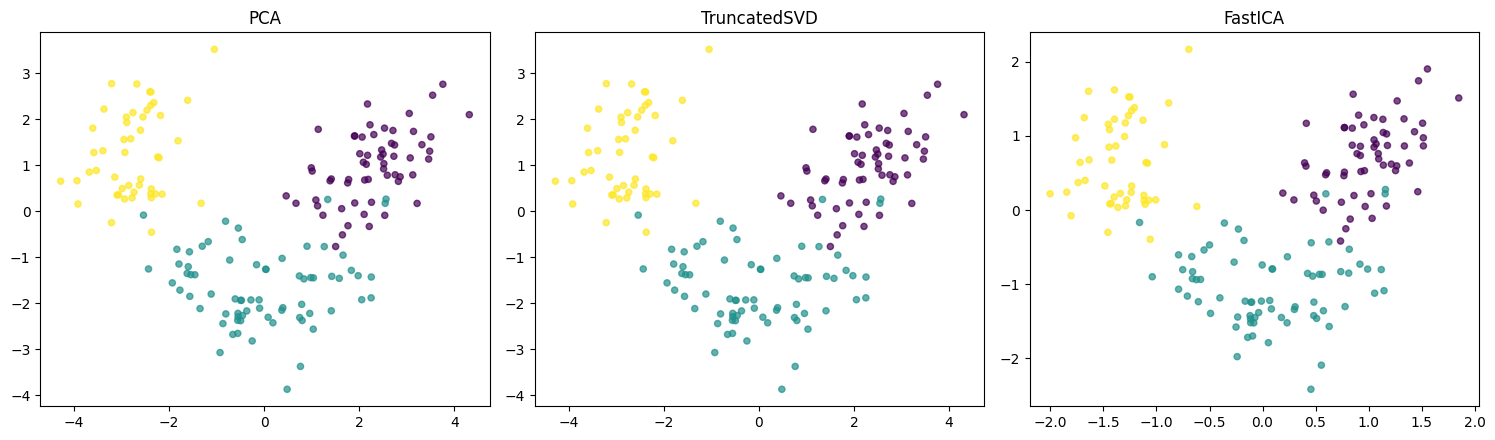

In [8]:
from sklearn.decomposition import PCA, TruncatedSVD, NMF, FastICA
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_wine

wine_dr = load_wine(as_frame=True)
Xw_dr = StandardScaler().fit_transform(wine_dr.data)

methods = {
    "PCA": PCA(n_components=2),
    "TruncatedSVD": TruncatedSVD(n_components=2),
    "FastICA": FastICA(n_components=2, random_state=42, max_iter=1000),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, method) in zip(axes, methods.items()):
    transformed = method.fit_transform(Xw_dr)
    scatter = ax.scatter(transformed[:, 0], transformed[:, 1], c=wine_dr.target, cmap="viridis", alpha=0.7, s=20)
    ax.set_title(name)

plt.tight_layout()
plt.show()


### Interpretation
All three methods reduce the same 13-dimensional wine dataset to 2 dimensions for visualization — note how well (or poorly) the three wine classes (color) separate in each 2D projection; **PCA** generally produces the most immediately interpretable, well-separated view for this kind of standard tabular data, which is exactly why it's the default first choice (formalized deeply in Chapter 35).

### Common Mistakes
- Reaching for `TruncatedSVD` on standard dense tabular data — it's specifically valuable for **sparse** data (its main advantage is not requiring centering, which would destroy sparsity); for dense data, plain `PCA` is simpler and standard.
- Applying dimensionality reduction *before* checking whether it's actually needed — if a dataset has a manageable number of features and no memory/visualization/multicollinearity concern, reduction may add complexity without real benefit.
- Not scaling features before `PCA`/most of these methods — since they operate on variance/covariance structure, unscaled features with different ranges would dominate the resulting components purely due to arbitrary scale, not genuine importance (the same lesson from Chapter 5, now applied to a new context).

### Best Practices
- Default to `PCA` for dense, standard tabular dimensionality reduction; `TruncatedSVD` specifically for sparse data.
- Always scale features first.
- Use dimensionality reduction deliberately — for genuine memory/compute constraints, multicollinearity handling, noise reduction, or visualization — not as an automatic preprocessing step.

### Interview Insight
**Q: When would you use `TruncatedSVD` instead of `PCA`?**
A: `TruncatedSVD` operates directly on the data without centering it first (subtracting the mean), which makes it compatible with sparse matrices — centering a sparse matrix would turn it dense (destroying the memory benefit sparsity provides), since most zero entries would become the small negative mean value instead. This makes `TruncatedSVD` the standard choice for high-dimensional sparse data like TF-IDF text representations (Chapter 63), where `PCA` would either fail or be computationally impractical; for standard dense tabular data, `PCA` remains the default.

### Quiz (Chapter 34)
1. What's the fundamental difference between feature selection and dimensionality reduction?
2. Why is `TruncatedSVD` preferred over `PCA` for sparse data specifically?
3. Why must features generally be scaled before dimensionality reduction?


---
# CHAPTER 35 — PCA DEEPLY

## 1. Concept
PCA finds new axes (principal components) — linear combinations of the original features — ordered by how much of the data's total variance each one captures. The first component captures the most variance possible along any single direction; each subsequent component captures the most *remaining* variance, subject to being orthogonal (uncorrelated) with all previous components.

## 2. Key Parameters and Fitted Attributes


In [9]:
pca_full = PCA(n_components=None)   # None = keep ALL components (no reduction yet, just to inspect variance structure)
pca_full.fit(Xw_dr)

print("explained_variance_ratio_ (fraction of total variance per component):")
print(pca_full.explained_variance_ratio_.round(3))
print("\nCumulative variance explained:")
print(np.cumsum(pca_full.explained_variance_ratio_).round(3))


explained_variance_ratio_ (fraction of total variance per component):
[0.362 0.192 0.111 0.071 0.066 0.049 0.042 0.027 0.022 0.019 0.017 0.013
 0.008]

Cumulative variance explained:
[0.362 0.554 0.665 0.736 0.802 0.851 0.893 0.92  0.942 0.962 0.979 0.992
 1.   ]


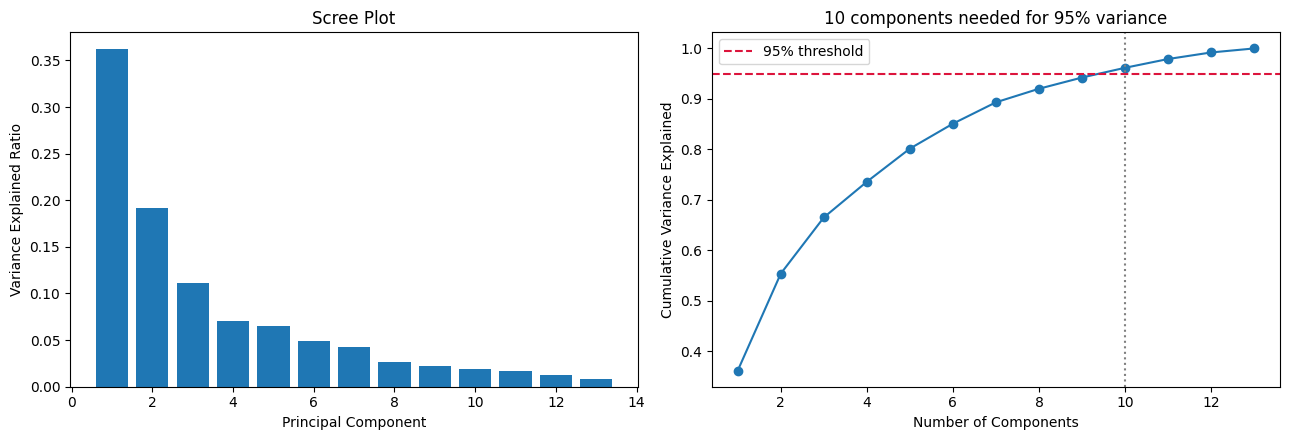

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(range(1, len(pca_full.explained_variance_ratio_) + 1), pca_full.explained_variance_ratio_, color="tab:blue")
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Variance Explained Ratio")
axes[0].set_title("Scree Plot")

cum_var = np.cumsum(pca_full.explained_variance_ratio_)
axes[1].plot(range(1, len(cum_var) + 1), cum_var, marker="o")
axes[1].axhline(0.95, color="crimson", linestyle="--", label="95% threshold")
n_for_95 = np.argmax(cum_var >= 0.95) + 1
axes[1].axvline(n_for_95, color="gray", linestyle=":")
axes[1].set_xlabel("Number of Components")
axes[1].set_ylabel("Cumulative Variance Explained")
axes[1].set_title(f"{n_for_95} components needed for 95% variance")
axes[1].legend()

plt.tight_layout()
plt.show()


### Parameter Explanation
| Parameter | Meaning |
|---|---|
| `n_components` | Integer (exact count), float in `(0,1)` (keep enough components to reach that fraction of variance — e.g., `n_components=0.95`), or `None` (keep all) |
| `whiten` | If `True`, additionally rescales each component to unit variance — useful when the downstream model benefits from equally-scaled inputs (e.g., before K-Means, Chapter 36) |
| `svd_solver` | `'auto'`, `'full'`, `'randomized'` — affects speed for very high-dimensional data, not the mathematical result (for `'full'` vs `'auto'`) |

### Fitted Attributes
| Attribute | Meaning |
|---|---|
| `.components_` | The actual principal axes — shape `(n_components, n_features)`; each row is a unit vector in original feature space |
| `.explained_variance_` | Raw variance (eigenvalue) captured by each component |
| `.explained_variance_ratio_` | Same, as a *fraction* of total variance — usually more directly useful |
| `.singular_values_` | The singular values from the underlying SVD decomposition |
| `.mean_` | The per-feature mean subtracted before projection (PCA always centers data internally) |

### Connection to NumPy Linear Algebra


In [11]:
# PCA is, under the hood, an eigendecomposition of the covariance matrix (or equivalently an SVD
# of the centered data matrix) -- let's confirm this DIRECTLY with raw NumPy linear algebra
cov_matrix = np.cov(Xw_dr, rowvar=False)
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# np.linalg.eigh returns eigenvalues in ASCENDING order -- PCA wants them descending
eigenvalues_sorted = eigenvalues[::-1]
explained_ratio_manual = eigenvalues_sorted / eigenvalues_sorted.sum()

print("First 3 explained variance ratios, Scikit-learn's PCA: ", pca_full.explained_variance_ratio_[:3].round(4))
print("First 3 explained variance ratios, manual NumPy eigh:  ", explained_ratio_manual[:3].round(4))
print("\nThese match (up to sign/ordering conventions) -- confirming PCA IS, literally,")
print("an eigendecomposition of the covariance matrix, computed via NumPy/SciPy's linear algebra under the hood.")


First 3 explained variance ratios, Scikit-learn's PCA:  [0.362  0.1921 0.1112]
First 3 explained variance ratios, manual NumPy eigh:   [0.362  0.1921 0.1112]

These match (up to sign/ordering conventions) -- confirming PCA IS, literally,
an eigendecomposition of the covariance matrix, computed via NumPy/SciPy's linear algebra under the hood.


### Common Mistakes
- Choosing `n_components` arbitrarily (e.g., always "2, for visualization") without checking the scree plot / cumulative variance to understand how much genuine information that retains.
- Forgetting PCA is **unsupervised** — it finds directions of maximum *variance* in `X`, with no knowledge of the target `y`; the direction of maximum variance is not guaranteed to be the direction most useful for predicting `y` (a real, non-obvious limitation, revisited critically in Chapter 98's traps).
- Interpreting individual principal components as directly meaningful business concepts without inspecting `.components_` — a component is a specific linear combination of original features, and can be meaningless or opaque unless you actually examine which original features load heavily onto it.

### Best Practices
- Use the scree plot / cumulative variance chart to choose `n_components` deliberately, or set `n_components=0.95` directly to target a specific variance-retention threshold.
- Always scale features before PCA.
- Inspect `.components_` to understand what each retained component actually represents in terms of original features, before treating it as a meaningful derived feature.

### Interview Insight
**Q: Is PCA always useful before training a supervised model? Give a scenario where it could hurt.**
A: No — PCA is entirely unsupervised, finding directions of maximum variance in the *feature* data alone, with no reference to the target. If the direction most predictive of the target happens to have *low* variance in the original feature space (a real, plausible scenario — a subtle but highly predictive signal buried in a low-variance feature), PCA could discard exactly that signal while retaining high-variance-but-less-predictive directions, actively hurting downstream model performance. This is why PCA should be applied deliberately (for genuine dimensionality/memory/multicollinearity/visualization reasons), validated empirically (does the model with PCA actually perform as well or better, per cross-validation), rather than treated as an automatically beneficial preprocessing step.

### Mini Exercise
Build two versions of a classification pipeline on the wine dataset — one with `PCA(n_components=5)` before `LogisticRegression`, one without any PCA step — and compare cross-validated accuracy to check empirically whether PCA helps or hurts on this specific dataset.

### Quiz (Chapter 35)
1. What does `.explained_variance_ratio_` represent, and how do you use it to choose `n_components`?
2. What linear algebra operation is PCA fundamentally equivalent to?
3. Why is PCA's "unsupervised" nature a genuine limitation, not just a technical detail?
4. What does `.components_` actually contain, and why must you inspect it before treating a component as meaningful?


---
# CHAPTER 36 — UNSUPERVISED LEARNING: CLUSTERING

## 1. Concept
Clustering groups similar observations together with **no target labels at all** — the algorithm must discover structure purely from the features themselves. Different algorithms make different assumptions about what a "cluster" looks like, making algorithm choice highly dependent on the data's actual shape.

## 2. The Family
| Algorithm | Assumes clusters are... | Needs `n_clusters` upfront? | Handles noise/outliers? |
|---|---|---|---|
| `KMeans` | Roughly spherical, similar size | Yes | No |
| `MiniBatchKMeans` | Same as KMeans | Yes | No — but scales to much larger data |
| `DBSCAN` | Dense regions separated by sparse regions, any shape | No | Yes — explicitly labels outliers as noise |
| `AgglomerativeClustering` | Hierarchical structure (nested groupings) | Yes (or a distance threshold) | No |
| `GaussianMixture` | Data generated from a mixture of Gaussian distributions (soft, probabilistic membership) | Yes | Somewhat, via low-probability assignment |


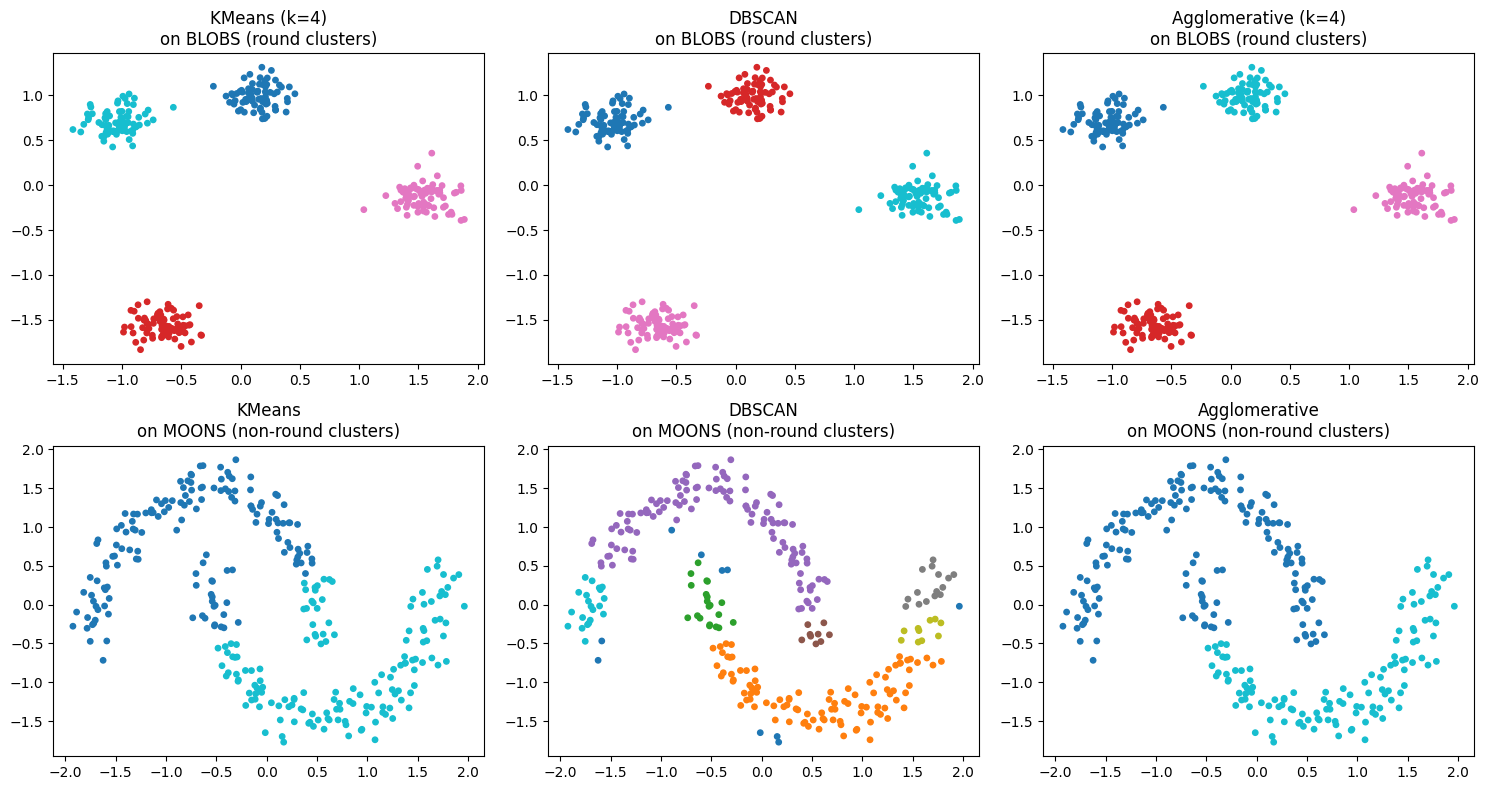

In [12]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.datasets import make_moons

# Two datasets: one where clusters are round (blobs), one where they're NOT (moons) -- illustrating
# why algorithm choice depends on the data's actual shape, not a universal "best" clusterer
X_blobs, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=42)
X_moons, _ = make_moons(n_samples=300, noise=0.08, random_state=42)

X_blobs_s = StandardScaler().fit_transform(X_blobs)
X_moons_s = StandardScaler().fit_transform(X_moons)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for col, (name, model) in enumerate([
    ("KMeans (k=4)", KMeans(n_clusters=4, random_state=42, n_init=10)),
    ("DBSCAN", DBSCAN(eps=0.3, min_samples=5)),
    ("Agglomerative (k=4)", AgglomerativeClustering(n_clusters=4)),
]):
    labels_blobs = model.fit_predict(X_blobs_s)
    axes[0, col].scatter(X_blobs_s[:, 0], X_blobs_s[:, 1], c=labels_blobs, cmap="tab10", s=15)
    axes[0, col].set_title(f"{name}\non BLOBS (round clusters)")

    model2 = model.__class__(**model.get_params()) if name != "DBSCAN" else DBSCAN(eps=0.2, min_samples=5)
    if "KMeans" in name:
        model2 = KMeans(n_clusters=2, random_state=42, n_init=10)
    elif "Agglomerative" in name:
        model2 = AgglomerativeClustering(n_clusters=2)
    labels_moons = model2.fit_predict(X_moons_s)
    axes[1, col].scatter(X_moons_s[:, 0], X_moons_s[:, 1], c=labels_moons, cmap="tab10", s=15)
    axes[1, col].set_title(f"{name.split(' (')[0]}\non MOONS (non-round clusters)")

plt.tight_layout()
plt.show()


### Interpretation
On the round "blobs" dataset, all three algorithms find essentially the correct 4 clusters. On the crescent-shaped "moons" dataset, `KMeans` and `AgglomerativeClustering` (with `n_clusters=2`) **fail** — they cut straight through each crescent, since both algorithms fundamentally assume roughly convex/spherical clusters. `DBSCAN`, which instead looks for dense regions of arbitrary shape separated by sparser regions, correctly identifies each crescent as its own cluster. **This is the single most important lesson of clustering algorithm selection**: there is no universally best clusterer — the right choice depends entirely on the data's actual geometric structure, which you often can't know for certain in advance, especially beyond 2D where visualization isn't directly possible.

### Parameter Explanation
| Parameter | Applies to | Meaning |
|---|---|---|
| `n_clusters` | KMeans, Agglomerative, GaussianMixture | Must be chosen — Chapter 37 covers how |
| `eps` | DBSCAN | Maximum distance for two points to be considered neighbors — the key, sensitive tuning parameter |
| `min_samples` | DBSCAN | Minimum neighbors (within `eps`) for a point to be a "core point" (cluster interior, not noise) |
| `n_init` | KMeans | Number of random centroid initializations tried (best result kept) — KMeans' result depends on random initialization, so `n_init > 1` (10 is a common default) reduces the risk of a poor local optimum |
| `linkage` | AgglomerativeClustering | How inter-cluster distance is measured during merging: `'ward'` (default, minimizes variance), `'complete'`, `'average'`, `'single'` |

### Common Mistakes
- Always reaching for `KMeans` by default without checking whether the data's actual cluster shapes are plausibly round — a genuinely common real-world mistake, since KMeans is the most well-known clustering algorithm but far from universally appropriate.
- Forgetting to scale features before clustering — like PCA and KNN, every one of these algorithms is distance-based and equally scale-sensitive.
- Not setting `n_init` (or relying on a too-low default) for `KMeans` — a single random initialization can converge to a poor local optimum; multiple initializations (keeping the best) substantially mitigates this.
- Treating DBSCAN-labeled "noise" points (label `-1`) as a bug rather than a genuine, useful output — DBSCAN explicitly identifying outliers is a real feature (Chapter 38's anomaly detection connects directly here), not something to filter out reflexively.

### Best Practices
- Visualize data (or a 2D PCA/dimensionality-reduced projection of it) before committing to a clustering algorithm, when at all feasible, to get intuition about cluster shape.
- Default to `KMeans` only when you have reason to believe clusters are roughly convex/spherical; reach for `DBSCAN` when cluster shape is unknown or plausibly irregular, and when explicit outlier identification is valuable.
- Always scale features first.

### Interview Insight
**Q: Your K-Means clustering result looks poor — clusters seem to cut through what should visually be single groups. What would you investigate?**
A: First, confirm features were scaled — unscaled features with different ranges can distort K-Means' Euclidean-distance-based clustering entirely on their own. If scaling isn't the issue, the more fundamental concern is that K-Means assumes roughly spherical, similarly-sized clusters; if the data's true clusters are non-convex (crescents, rings, highly elongated shapes) or have very different densities/sizes, K-Means will fundamentally struggle regardless of tuning. In that case, `DBSCAN` (arbitrary shape, density-based) or `AgglomerativeClustering` with a non-Euclidean linkage might be more appropriate — visualizing the data (directly, or via a 2D PCA projection) is the fastest way to build intuition about which assumption actually fits.

### Quiz (Chapter 36)
1. Why does K-Means fail on the "moons" dataset while DBSCAN succeeds?
2. What does DBSCAN's `eps` parameter control, and why is it the most sensitive tuning parameter?
3. Why does K-Means need `n_init > 1`?
4. What does a DBSCAN label of `-1` mean, and why is it a genuine feature, not a bug?


---
# CHAPTER 37 — CLUSTER EVALUATION

## 1. Concept
Without ground-truth labels, evaluating cluster **quality** requires metrics computed purely from the data's geometry and the assigned cluster labels — these also help choose `n_clusters` when it isn't known in advance (the classic "elbow method"/silhouette approach).

## 2. The Three Metrics
| Metric | Range | Interpretation | Needs ground truth? |
|---|---|---|---|
| **Silhouette Score** | `[-1, 1]` | How similar each point is to its own cluster vs. the nearest other cluster — higher is better | No |
| **Calinski-Harabasz** | `[0, ∞)` | Ratio of between-cluster to within-cluster dispersion — higher is better | No |
| **Davies-Bouldin** | `[0, ∞)` | Average similarity between each cluster and its most similar other cluster — **lower** is better | No |


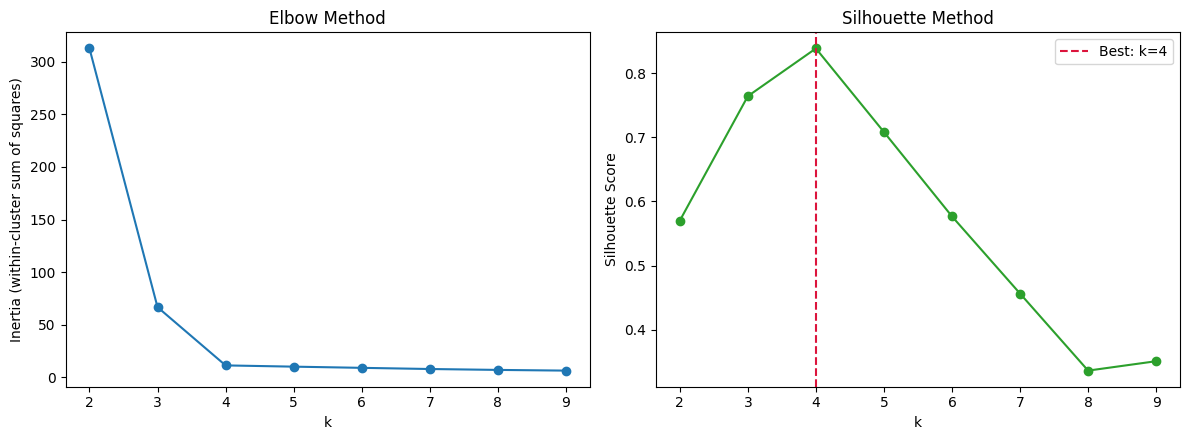

In [13]:
from sklearn.metrics import silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score

# The classic "elbow method" extended with silhouette score -- choosing n_clusters WITHOUT ground truth
k_range = range(2, 10)
inertias = []
silhouettes = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_blobs_s)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_blobs_s, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(list(k_range), inertias, marker="o")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia (within-cluster sum of squares)")
axes[0].set_title("Elbow Method")

axes[1].plot(list(k_range), silhouettes, marker="o", color="tab:green")
best_k = list(k_range)[np.argmax(silhouettes)]
axes[1].axvline(best_k, color="crimson", linestyle="--", label=f"Best: k={best_k}")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Method")
axes[1].legend()

plt.tight_layout()
plt.show()


### Line-by-Line Explanation
- `km.inertia_` — the within-cluster sum of squared distances to each point's assigned centroid; **always decreases** as `k` increases (more clusters can only fit the data at least as well), which is exactly why the "elbow method" looks for a *bend* in the curve (diminishing returns) rather than the minimum — there's no true minimum other than `k = n_samples`.
- `silhouette_score` — unlike inertia, this has a genuine, non-trivial optimum — it directly penalizes both poorly-separated clusters (points close to a neighboring cluster) and, implicitly, too many/too few clusters, making it a more principled way to actually *choose* `k` than eyeballing an elbow bend.

### Comparing All Three Metrics Across Algorithms


In [14]:
results_cluster = {}
for name, model in [
    ("KMeans (k=4)", KMeans(n_clusters=4, random_state=42, n_init=10)),
    ("KMeans (k=2, WRONG)", KMeans(n_clusters=2, random_state=42, n_init=10)),
    ("DBSCAN", DBSCAN(eps=0.3, min_samples=5)),
]:
    labels = model.fit_predict(X_blobs_s)
    if len(set(labels)) > 1:   # metrics require at least 2 clusters
        results_cluster[name] = {
            "Silhouette (higher better)": silhouette_score(X_blobs_s, labels),
            "Calinski-Harabasz (higher better)": calinski_harabasz_score(X_blobs_s, labels),
            "Davies-Bouldin (lower better)": davies_bouldin_score(X_blobs_s, labels),
        }

print(pd.DataFrame(results_cluster).T.round(3))


                     Silhouette (higher better)  \
KMeans (k=4)                              0.839   
KMeans (k=2, WRONG)                       0.570   
DBSCAN                                    0.839   

                     Calinski-Harabasz (higher better)  \
KMeans (k=4)                                  5132.391   
KMeans (k=2, WRONG)                            273.733   
DBSCAN                                        5132.391   

                     Davies-Bouldin (lower better)  
KMeans (k=4)                                 0.224  
KMeans (k=2, WRONG)                          0.555  
DBSCAN                                       0.224  


### Interpretation
The deliberately-wrong `KMeans(k=2)` (fitting the same 4-blob data with too few clusters) should score visibly worse across all three metrics than the correct `k=4` — a useful sanity check confirming these metrics genuinely respond to cluster quality, not just producing arbitrary numbers. Comparing algorithms this way (rather than only within one algorithm's own `k` sweep) is exactly how you'd choose between, e.g., KMeans and DBSCAN on a genuinely unfamiliar dataset when ground truth isn't available.

### Common Mistakes
- Using inertia alone (the raw elbow method) to choose `k` without silhouette or other confirmation — inertia's monotonic decrease makes the "elbow" genuinely subjective and sometimes ambiguous; silhouette gives an actual, non-monotonic optimum to point to.
- Comparing Calinski-Harabasz or Davies-Bouldin scores across **datasets** of different sizes/scales as if they were directly comparable absolute benchmarks — like mutual information (Chapter 33), these are most reliable for *relative* comparison within one fixed dataset/feature-scaling setup.
- Applying silhouette score to a dataset with DBSCAN-labeled noise points (`-1`) without deciding how to handle them — usually excluded from the calculation deliberately, since "noise" isn't a genuine cluster to be scored.

### Best Practices
- Use silhouette score as the primary, more principled way to choose `n_clusters`, with the elbow/inertia plot as a secondary sanity check.
- Compute multiple cluster evaluation metrics together, exactly as for supervised evaluation metrics (Chapter 27) — no single unsupervised metric captures every aspect of cluster quality.

### Interview Insight
**Q: Why can't you simply pick the `n_clusters` that minimizes K-Means' inertia?**
A: Inertia (within-cluster sum of squared distances) mechanically decreases as `n_clusters` increases — in the extreme, `n_clusters = n_samples` gives inertia of exactly zero (every point is its own cluster), which is clearly not a meaningful clustering result. Inertia alone has no genuine minimum to select for; it requires the more subjective "elbow" heuristic (looking for a bend where additional clusters give diminishing returns) or, more principled, a metric like silhouette score, which has a genuine non-trivial optimum reflecting actual cluster separation and cohesion quality, not just raw within-cluster tightness.

### Quiz (Chapter 37)
1. Why does K-Means' inertia always decrease as `n_clusters` increases, and why does that make it unsuitable alone for choosing `k`?
2. What does a high silhouette score indicate about a point's cluster assignment?
3. Which of the three cluster evaluation metrics wants to be minimized rather than maximized?


---
# CHAPTER 38 — ANOMALY DETECTION

## 1. Concept
Anomaly/outlier detection identifies observations that differ substantially from the majority — directly connecting to the Matplotlib course's Chapter 68 "outlier triage" lesson, now with dedicated algorithms rather than purely visual/statistical (IQR-based) detection.

## 2. The Family
| Algorithm | Idea | Notes |
|---|---|---|
| `IsolationForest` | Anomalies are "easier to isolate" via random splits (fewer splits needed to separate them) | Fast, scales well, a strong general-purpose default |
| `LocalOutlierFactor` | Compares a point's local density to its neighbors' local density | Good for anomalies that are only unusual *relative to their local neighborhood* |
| `OneClassSVM` | Learns a boundary around the "normal" data region | Effective but computationally similar to standard SVM's scaling limitations (Chapter 17) |
| `EllipticEnvelope` | Assumes normal data follows a Gaussian distribution, fits an ellipse | Only appropriate when that Gaussian assumption is plausible |


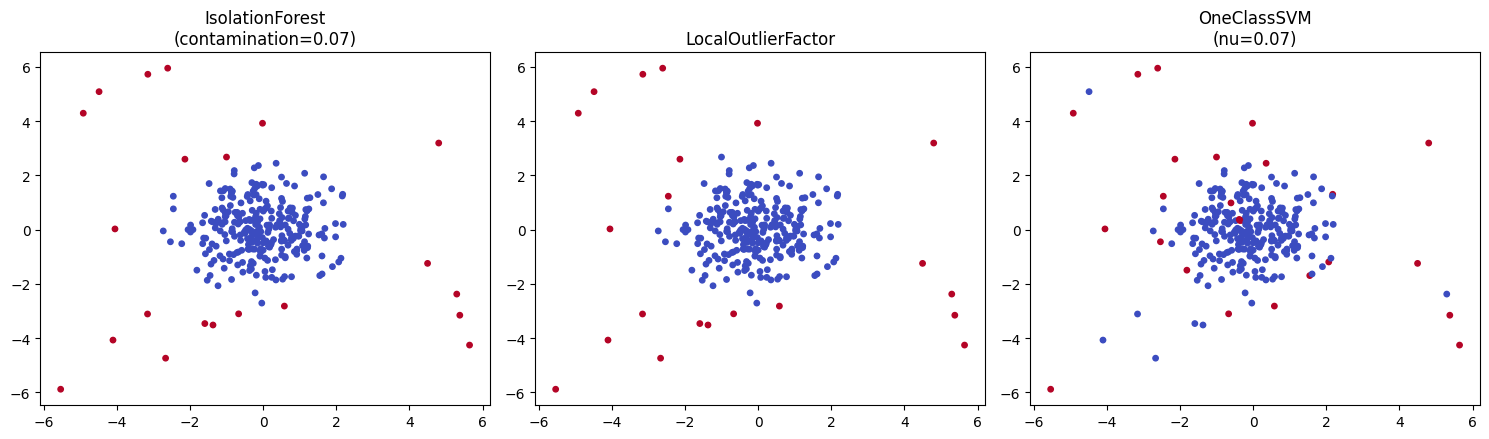

IsolationForest      agreement with true anomaly labels: 97.67%
LocalOutlierFactor   agreement with true anomaly labels: 97.67%
OneClassSVM          agreement with true anomaly labels: 92.33%


In [15]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

np.random.seed(15)
normal_data = np.random.normal(0, 1, (280, 2))
anomalies = np.random.uniform(-6, 6, (20, 2))
X_anom = np.vstack([normal_data, anomalies])
true_is_anomaly = np.array([0] * 280 + [1] * 20)   # kept ONLY for visualization/evaluation, not given to the models

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

iso = IsolationForest(contamination=0.07, random_state=42)
iso_labels = iso.fit_predict(X_anom)   # returns -1 for anomaly, 1 for normal
axes[0].scatter(X_anom[:, 0], X_anom[:, 1], c=(iso_labels == -1), cmap="coolwarm", s=15)
axes[0].set_title("IsolationForest\n(contamination=0.07)")

lof = LocalOutlierFactor(n_neighbors=20, contamination=0.07)
lof_labels = lof.fit_predict(X_anom)
axes[1].scatter(X_anom[:, 0], X_anom[:, 1], c=(lof_labels == -1), cmap="coolwarm", s=15)
axes[1].set_title("LocalOutlierFactor")

ocsvm = OneClassSVM(nu=0.07, gamma="scale")
ocsvm_labels = ocsvm.fit_predict(X_anom)
axes[2].scatter(X_anom[:, 0], X_anom[:, 1], c=(ocsvm_labels == -1), cmap="coolwarm", s=15)
axes[2].set_title("OneClassSVM\n(nu=0.07)")

plt.tight_layout()
plt.show()

for name, labels in [("IsolationForest", iso_labels), ("LocalOutlierFactor", lof_labels), ("OneClassSVM", ocsvm_labels)]:
    detected = (labels == -1).astype(int)
    agreement = (detected == true_is_anomaly).mean()
    print(f"{name:<20} agreement with true anomaly labels: {agreement:.2%}")


### Parameter Explanation
| Parameter | Applies to | Meaning |
|---|---|---|
| `contamination` | IsolationForest, LocalOutlierFactor | Expected **proportion** of anomalies in the data — directly sets the decision threshold; requires a reasonable estimate/domain knowledge |
| `n_neighbors` | LocalOutlierFactor | How many neighbors define "local" density |
| `nu` | OneClassSVM | Upper bound on the fraction of training errors / anomalies (conceptually similar role to `contamination`) |

### Novelty Detection vs. Outlier Detection — A Critical Distinction
- **Outlier detection** (what's shown above): `.fit_predict()` on one dataset, identifying anomalies **within that same dataset**.
- **Novelty detection**: fit on data assumed to be "normal" (clean), then use `.predict()` on **new, incoming** data to flag anything that doesn't match the learned normal pattern. `LocalOutlierFactor` requires `novelty=True` explicitly to support this second mode (`.predict()` is disabled by default, specifically to prevent the common mistake of accidentally using it as if it were novelty detection when it was fit in outlier-detection mode).

### Common Mistakes
- Setting `contamination` to a wildly inaccurate guess — since it directly determines the anomaly threshold, an unrealistic contamination estimate directly produces too many or too few flagged points, regardless of how well the underlying algorithm is actually working.
- Using `LocalOutlierFactor` for novelty detection (predicting on new data) without setting `novelty=True` at construction — it will otherwise error or misbehave, since its default mode assumes you're evaluating outliers within the same fitted dataset.
- Treating anomaly detection output as automatically meaning "these should be deleted" — the same Chapter 68 (Matplotlib course) triage principle applies identically here: a flagged anomaly might be a data error, or it might be a genuinely rare, valuable event (fraud, a critical equipment failure) that the whole point of the exercise is to *find*, not discard.

### Best Practices
- Set `contamination` using genuine domain knowledge/historical rates when available, rather than an arbitrary default.
- Use `novelty=True` explicitly with `LocalOutlierFactor` whenever the actual goal is scoring new incoming data, not just analyzing a fixed historical dataset.
- Investigate flagged anomalies individually before deciding whether each represents an error to fix or a genuine rare event to act on.

### Interview Insight
**Q: You want to build a fraud-detection system that scores each NEW incoming transaction in real time. Why can't you simply use `LocalOutlierFactor.fit_predict()` on each new transaction as it arrives?**
A: `LocalOutlierFactor`'s default mode is **outlier detection** — it's designed to be fit once on a fixed dataset and identify anomalies *within that same dataset*, computing each point's local density relative to its neighbors in that batch. It has no built-in mechanism to score a single new point against a previously-learned "normal" pattern unless explicitly configured with `novelty=True`, which enables a separate `.predict()` method for exactly this purpose — fit once on historical "normal" transaction data, then call `.predict()` on each new transaction as it streams in. Using `fit_predict()` repeatedly on individual new transactions (its default mode) wouldn't even be meaningful, since local density requires a genuine batch of neighboring points to compare against.

### Quiz (Chapter 38)
1. What does `IsolationForest`'s core idea ("easier to isolate") mean conceptually?
2. What's the critical difference between outlier detection and novelty detection, and which parameter enables the latter for `LocalOutlierFactor`?
3. Why shouldn't a flagged anomaly automatically be deleted from the dataset?
4. Why does `contamination` need a genuine, informed estimate rather than an arbitrary default?

### Chapter 38 Summary
- Anomaly detection algorithms (IsolationForest, LocalOutlierFactor, OneClassSVM, EllipticEnvelope) each make different structural assumptions about what "normal" looks like.
- Outlier detection (analyze a fixed dataset) and novelty detection (score new incoming data against a learned normal pattern) are genuinely different modes — know which one your application actually needs.
- Exactly like clustering, flagged anomalies require human judgment about whether they represent errors or genuinely valuable rare events.

---

## END OF NOTEBOOK 7 — What You Should Now Be Able To Do
- Apply filter, wrapper, and embedded feature selection methods appropriately, and explain when each might miss a genuinely important feature.
- Use mutual information to detect non-linear feature-target relationships that linear tests would miss.
- Choose between PCA, TruncatedSVD, NMF, and FastICA based on data structure (dense/sparse, non-negative, independence needs).
- Explain PCA as literally an eigendecomposition/SVD, choose `n_components` deliberately via the scree plot, and articulate PCA's key limitation (unsupervised, can discard predictive low-variance signal).
- Select the correct clustering algorithm based on the data's actual geometric structure (KMeans for round clusters, DBSCAN for arbitrary shape + outlier identification).
- Evaluate clusters without ground truth using silhouette score (and know why inertia alone can't choose `k`).
- Apply anomaly detection algorithms correctly, distinguishing outlier detection from novelty detection, and treat flagged anomalies with the same investigative judgment as any other outlier-triage workflow.

## Before Moving to Notebook 8 (Chapters 39–45: Semi-Supervised Learning, Composed Estimators, Meta-Estimators, Multi-Class Classification, Multi-Label Classification, Multi-Output Learning, Imbalanced Data)

